# Partie 1
## 1. Série y = sin(x) et RNN

In [21]:
import torch
import torch.nn as nn
torch.manual_seed(42)

periode = torch.linspace(0, 20, 200)
serie = torch.sin(periode)
longueur_sequence = 10
X = torch.stack([
    serie[i:i + longueur_sequence]
    for i in range(len(serie) - longueur_sequence)
])
y = torch.stack([
    serie[i + longueur_sequence]
    for i in range(len(serie) - longueur_sequence)
])
X = X.unsqueeze(-1) 
y = y.unsqueeze(-1)

X_train, y_train = X[:150], y[:150]
X_test, y_test = X[150:], y[150:]

Text(0, 0.5, 'y')

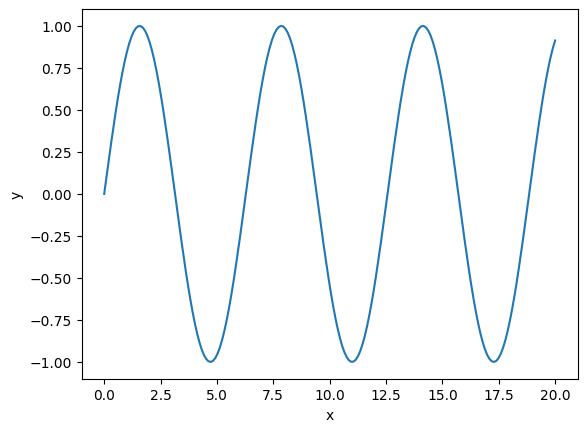

In [22]:
import matplotlib.pyplot as plt
plt.plot(periode, serie)
plt.xlabel("x")
plt.ylabel("y")

In [23]:
class SimpleRNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.rnn = nn.RNN(
            input_size=1,     
            hidden_size=16,  
            batch_first=True
        )

        self.sortie = nn.Linear(16, 1)

    def forward(self, x):
        etats, _ = self.rnn(x)

        dernier_etat = etats[:, -1, :]  

        return self.sortie(dernier_etat)


modele = SimpleRNN()
critere = nn.MSELoss()
optimiseur = torch.optim.Adam(modele.parameters(), lr=0.01)

In [24]:
modele.train()

for epoch in range(300):
    predictions = modele(X_train)
    perte = critere(predictions, y_train)

    optimiseur.zero_grad()  
    perte.backward()      
    optimiseur.step() 

    if (epoch + 1) % 50 == 0:
        print(f"Epoch {epoch + 1:3d} | Erreur : {perte.item():.6f}")



modele.eval()

with torch.no_grad():
    predictions = modele(X_test)
    erreur_test = critere(predictions, y_test)

print(f"\nErreur de test : {erreur_test.item():.6f}")
print(f"Valeur réelle  : {y_test[0].item():.4f}")
print(f"Valeur prédite : {predictions[0].item():.4f}")

Epoch  50 | Erreur : 0.001277
Epoch 100 | Erreur : 0.000504
Epoch 150 | Erreur : 0.000223
Epoch 200 | Erreur : 0.000103
Epoch 250 | Erreur : 0.000049
Epoch 300 | Erreur : 0.000025

Erreur de test : 0.000028
Valeur réelle  : -0.3639
Valeur prédite : -0.3601


In [25]:
predictions.shape

torch.Size([40, 1])

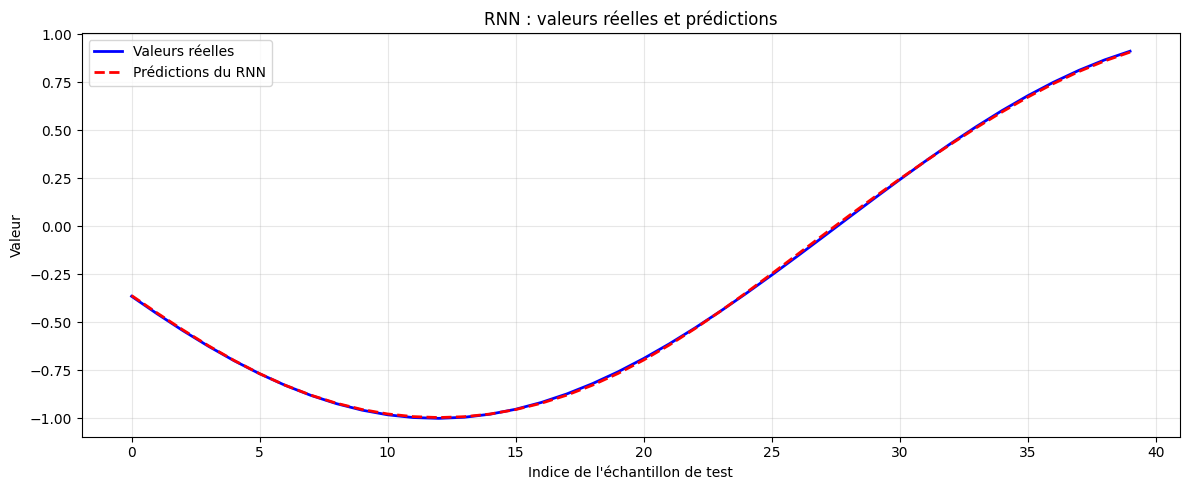

In [26]:
import matplotlib.pyplot as plt

valeurs_reelles = y_test.detach().cpu().numpy().reshape(-1)
valeurs_predites = predictions.detach().cpu().numpy().reshape(-1)

plt.figure(figsize=(12, 5))

plt.plot(
    valeurs_reelles,
    label="Valeurs réelles",
    color="blue",
    linewidth=2
)

plt.plot(
    valeurs_predites,
    label="Prédictions du RNN",
    color="red",
    linestyle="--",
    linewidth=2
)

plt.title("RNN : valeurs réelles et prédictions")
plt.xlabel("Indice de l'échantillon de test")
plt.ylabel("Valeur")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 2. LSTM

In [27]:
import torch
import torch.nn as nn

torch.manual_seed(42)

serie = torch.sin(torch.linspace(0, 20, 200))
longueur_sequence = 10

X = torch.stack([
    serie[i:i + longueur_sequence]
    for i in range(len(serie) - longueur_sequence)
])

y = torch.stack([
    serie[i + longueur_sequence]
    for i in range(len(serie) - longueur_sequence)
])

X = X.unsqueeze(-1)  
y = y.unsqueeze(-1)


X_train, y_train = X[:150], y[:150]
X_test, y_test = X[150:], y[150:]



class SimpleLSTM(nn.Module):
    def __init__(self):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=1,     
            hidden_size=16,   
            num_layers=1,   
            batch_first=True
        )

        self.sortie = nn.Linear(16, 1)

    def forward(self, x):

        etats, (h_final, c_final) = self.lstm(x)

        dernier_etat = etats[:, -1, :]  

        return self.sortie(dernier_etat)


modele = SimpleLSTM()
critere = nn.MSELoss()
optimiseur = torch.optim.Adam(modele.parameters(), lr=0.01)



modele.train()

for epoch in range(300):
    predictions = modele(X_train)
    perte = critere(predictions, y_train)

    optimiseur.zero_grad()
    perte.backward()
    optimiseur.step()

    if (epoch + 1) % 50 == 0:
        print(f"Epoch {epoch + 1:3d} | Erreur : {perte.item():.6f}")



modele.eval()

with torch.no_grad():
    predictions = modele(X_test)
    erreur_test = critere(predictions, y_test)

print(f"\nErreur de test : {erreur_test.item():.6f}")
print(f"Valeur réelle  : {y_test[0].item():.4f}")
print(f"Valeur prédite : {predictions[0].item():.4f}")

Epoch  50 | Erreur : 0.003562
Epoch 100 | Erreur : 0.000248
Epoch 150 | Erreur : 0.000043
Epoch 200 | Erreur : 0.000006
Epoch 250 | Erreur : 0.000004
Epoch 300 | Erreur : 0.000003

Erreur de test : 0.000003
Valeur réelle  : -0.3639
Valeur prédite : -0.3622


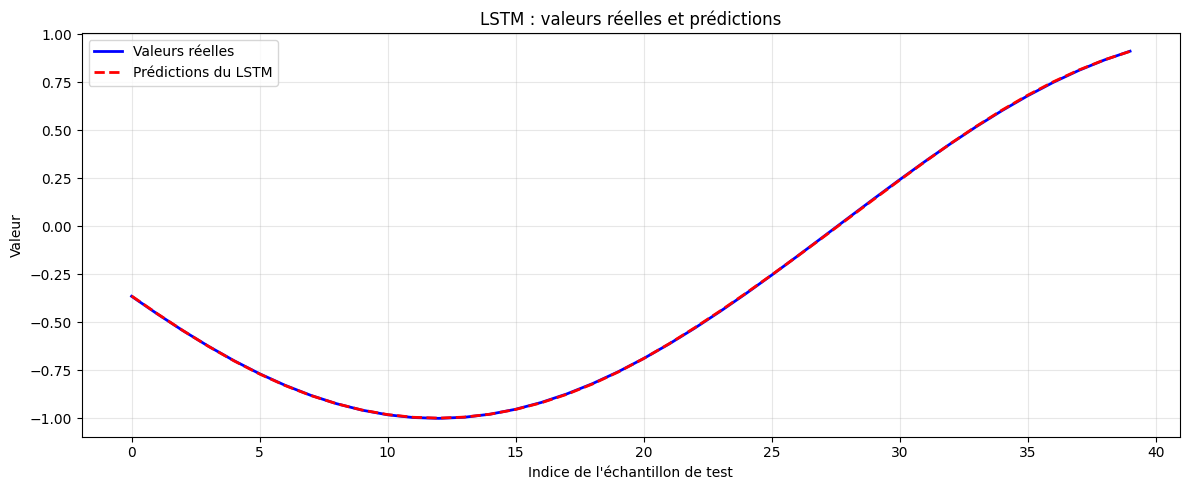

In [28]:
import matplotlib.pyplot as plt

valeurs_reelles = y_test.detach().cpu().numpy().reshape(-1)
valeurs_predites = predictions.detach().cpu().numpy().reshape(-1)

plt.figure(figsize=(12, 5))

plt.plot(
    valeurs_reelles,
    label="Valeurs réelles",
    color="blue",
    linewidth=2
)

plt.plot(
    valeurs_predites,
    label="Prédictions du LSTM",
    color="red",
    linestyle="--",
    linewidth=2
)

plt.title("LSTM : valeurs réelles et prédictions")
plt.xlabel("Indice de l'échantillon de test")
plt.ylabel("Valeur")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 3. Transformer

In [29]:
import torch
import torch.nn as nn

torch.manual_seed(42)

serie = torch.sin(torch.linspace(0, 20, 200))
longueur_sequence = 10

X = torch.stack([
    serie[i:i + longueur_sequence]
    for i in range(len(serie) - longueur_sequence)
])

y = torch.stack([
    serie[i + longueur_sequence]
    for i in range(len(serie) - longueur_sequence)
])

X = X.unsqueeze(-1) 
y = y.unsqueeze(-1) 

X_train, y_train = X[:150], y[:150]
X_test, y_test = X[150:], y[150:]


class MiniTransformer(nn.Module):
    def __init__(self, longueur_max=10):
        super().__init__()

        dimension = 16

        self.projection = nn.Linear(1, dimension)

        self.positions = nn.Embedding(longueur_max, dimension)

        couche = nn.TransformerEncoderLayer(
            d_model=dimension,       
            nhead=2,                 
            dim_feedforward=32,      
            dropout=0.0,             
            batch_first=True
        )

        self.encodeur = nn.TransformerEncoder(
            couche,
            num_layers=1
        )

        self.sortie = nn.Linear(dimension, 1)

    def forward(self, x):
        longueur = x.size(1)

        x = self.projection(x)

        indices = torch.arange(longueur, device=x.device)
        positions = self.positions(indices)

        x = x + positions.unsqueeze(0)

        representations = self.encodeur(x) 

        derniere_position = representations[:, -1, :] 

        return self.sortie(derniere_position)


modele = MiniTransformer(longueur_max=longueur_sequence)
critere = nn.MSELoss()
optimiseur = torch.optim.Adam(modele.parameters(), lr=0.01)

modele.train()

for epoch in range(300):
    predictions = modele(X_train)
    perte = critere(predictions, y_train)

    optimiseur.zero_grad()
    perte.backward()
    optimiseur.step()

    if (epoch + 1) % 50 == 0:
        print(f"Epoch {epoch + 1:3d} | Erreur : {perte.item():.6f}")


modele.eval()

with torch.no_grad():
    predictions = modele(X_test)
    erreur_test = critere(predictions, y_test)

print(f"\nErreur de test : {erreur_test.item():.6f}")
print(f"Valeur réelle  : {y_test[0].item():.4f}")
print(f"Valeur prédite : {predictions[0].item():.4f}")

Epoch  50 | Erreur : 0.001504
Epoch 100 | Erreur : 0.000110
Epoch 150 | Erreur : 0.000026
Epoch 200 | Erreur : 0.000012
Epoch 250 | Erreur : 0.000007
Epoch 300 | Erreur : 0.000004

Erreur de test : 0.000006
Valeur réelle  : -0.3639
Valeur prédite : -0.3662


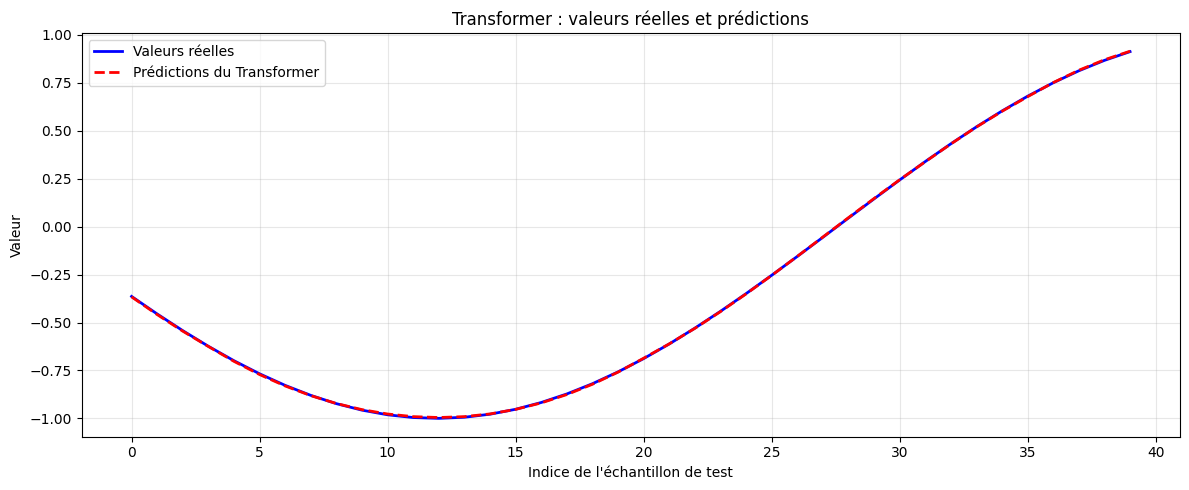

In [30]:
import matplotlib.pyplot as plt

valeurs_reelles = y_test.detach().cpu().numpy().reshape(-1)
valeurs_predites = predictions.detach().cpu().numpy().reshape(-1)

plt.figure(figsize=(12, 5))

plt.plot(
    valeurs_reelles,
    label="Valeurs réelles",
    color="blue",
    linewidth=2
)

plt.plot(
    valeurs_predites,
    label="Prédictions du Transformer",
    color="red",
    linestyle="--",
    linewidth=2
)

plt.title("Transformer : valeurs réelles et prédictions")
plt.xlabel("Indice de l'échantillon de test")
plt.ylabel("Valeur")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 4. GPT (prédire la suite d'un texte)

In [31]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

nom_modele = "gpt2"

tokenizer = AutoTokenizer.from_pretrained(nom_modele)
modele = AutoModelForCausalLM.from_pretrained(nom_modele)

tokenizer.pad_token = tokenizer.eos_token
modele.config.pad_token_id = tokenizer.pad_token_id

modele.eval()

texte = "Artificial intelligence can help people"

entrees = tokenizer(
    texte,
    return_tensors="pt"
)

print("Dimensions de l'entrée :", entrees["input_ids"].shape)


with torch.no_grad():
    sortie = modele.generate(
        **entrees,
        max_new_tokens=50,       
        do_sample=True,          
        temperature=0.8,       
        top_p=0.9,  
        pad_token_id=tokenizer.pad_token_id
    )


texte_genere = tokenizer.decode(
    sortie[0],
    skip_special_tokens=True
)

print("\nTexte généré :")
print(texte_genere)

Loading weights: 100%|██████████| 148/148 [00:00<00:00, 2084.36it/s]


Dimensions de l'entrée : torch.Size([1, 6])

Texte généré :
Artificial intelligence can help people and organizations create jobs and build organizations, which in turn will spur growth and prosperity.

However, when a company becomes more complex, it's likely that its users will be less interested in technology. The companies that make the software that makes things


## 5. BERT

In [32]:
import torch
from transformers import AutoTokenizer, AutoModelForMaskedLM


nom_modele = "bert-base-multilingual-cased"

tokenizer = AutoTokenizer.from_pretrained(nom_modele)
modele = AutoModelForMaskedLM.from_pretrained(nom_modele)

modele.eval()


texte = f"Rabat est la {tokenizer.mask_token} Maroc."

entrees = tokenizer(
    texte,
    return_tensors="pt"
)

print("Texte :", texte)
print("Dimensions de l'entrée :", entrees["input_ids"].shape)

position_masque = (
    entrees["input_ids"][0] == tokenizer.mask_token_id
).nonzero(as_tuple=True)[0].item()


with torch.no_grad():
    sortie = modele(**entrees)

scores = sortie.logits[0, position_masque, :]

probabilites = torch.softmax(scores, dim=-1)

top_probabilites, top_indices = torch.topk(probabilites, k=5)


print("\nPropositions de BERT :")

for probabilite, indice in zip(top_probabilites, top_indices):
    token = tokenizer.decode([indice.item()]).strip()

    phrase = texte.replace(tokenizer.mask_token, token)

    print(f"{probabilite.item():.2%} | {phrase}")

Loading weights: 100%|██████████| 202/202 [00:00<00:00, 5021.27it/s]
[transformers] BertForMaskedLM LOAD REPORT from: bert-base-multilingual-cased
Key                         | Status     |  | 
----------------------------+------------+--+-
bert.pooler.dense.weight    | UNEXPECTED |  | 
cls.seq_relationship.weight | UNEXPECTED |  | 
bert.pooler.dense.bias      | UNEXPECTED |  | 
cls.seq_relationship.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Texte : Rabat est la [MASK] Maroc.
Dimensions de l'entrée : torch.Size([1, 8])

Propositions de BERT :
42.90% | Rabat est la capitale Maroc.
20.66% | Rabat est la du Maroc.
6.23% | Rabat est la de Maroc.
3.46% | Rabat est la ville Maroc.
1.67% | Rabat est la Rabat Maroc.


# Partie 2
## Exercice 1 : consommation électrique

In [1]:
import numpy as np
import pandas as pd
import torch
from torch.utils.data import TensorDataset, DataLoader

df = pd.read_csv(
    "household_power_consumption.txt",
    sep=";",
    na_values=["?"],
    low_memory=False,
)

df["datetime"] = pd.to_datetime(
    df["Date"] + " " + df["Time"],
    format="%d/%m/%Y %H:%M:%S",
)

puissance = pd.to_numeric(df["Global_active_power"], errors="coerce")
puissance.index = pd.DatetimeIndex(df["datetime"])

horaire = puissance.resample("h").agg(["mean", "count"])
serie = horaire["mean"].where(horaire["count"] >= 45)

n = len(serie)
fin_train = int(0.70 * n)
fin_val = int(0.85 * n)

moyenne = serie.iloc[:fin_train].mean()
ecart_type = serie.iloc[:fin_train].std()
valeurs = ((serie - moyenne) / ecart_type).to_numpy()

fenetre = 24
X, y, dates_cibles = [], [], []

for i in range(fenetre, n):
    sequence = valeurs[i - fenetre:i]
    cible = valeurs[i]

    if np.isfinite(sequence).all() and np.isfinite(cible):
        X.append(sequence)
        y.append(cible)
        dates_cibles.append(i)

X = torch.tensor(np.array(X), dtype=torch.float32).unsqueeze(-1)
y = torch.tensor(np.array(y), dtype=torch.float32).unsqueeze(-1)
dates_cibles = np.array(dates_cibles)

train_mask = dates_cibles < fin_train
val_mask = (dates_cibles >= fin_train) & (dates_cibles < fin_val)
test_mask = dates_cibles >= fin_val

train_loader = DataLoader(
    TensorDataset(X[train_mask], y[train_mask]),
    batch_size=64,
    shuffle=True,
)
val_loader = DataLoader(
    TensorDataset(X[val_mask], y[val_mask]),
    batch_size=64,
)
test_loader = DataLoader(
    TensorDataset(X[test_mask], y[test_mask]),
    batch_size=64,
)

#### Solution — Exercice 1

In [2]:
import copy
import math
import matplotlib.pyplot as plt
import torch.nn as nn

appareil = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(0)


class EnergyTransformer(nn.Module):
    def __init__(self, longueur_fenetre=24, dimension=32, nb_tetes=4, nb_couches=2):
        super().__init__()
        self.projection = nn.Linear(1, dimension)
        self.positions = nn.Embedding(longueur_fenetre, dimension)
        couche = nn.TransformerEncoderLayer(
            d_model=dimension,
            nhead=nb_tetes,
            dim_feedforward=128,
            dropout=0.1,
            batch_first=True,
        )
        self.encodeur = nn.TransformerEncoder(couche, num_layers=nb_couches, enable_nested_tensor=False)
        self.sortie = nn.Linear(dimension, 1)

    def forward(self, x):
        indices = torch.arange(x.size(1), device=x.device)
        x = self.projection(x) + self.positions(indices)  
        x = self.encodeur(x)                             
        return self.sortie(x[:, -1, :])                 


def entrainer_energie(modele, loader_train, loader_val, nb_epoques=20, lr=1e-3):
    modele = modele.to(appareil)
    critere = nn.MSELoss()
    optimiseur = torch.optim.Adam(modele.parameters(), lr=lr)
    meilleure_val, meilleur_etat, historique = float("inf"), None, []

    for epoque in range(1, nb_epoques + 1):
        modele.train()
        somme, nb = 0.0, 0
        for xb, yb in loader_train:
            xb, yb = xb.to(appareil), yb.to(appareil)
            perte = critere(modele(xb), yb)
            optimiseur.zero_grad()
            perte.backward()
            optimiseur.step()
            somme += perte.item() * len(xb)
            nb += len(xb)
        perte_train = somme / nb

        modele.eval()
        somme, nb = 0.0, 0
        with torch.no_grad():
            for xb, yb in loader_val:
                xb, yb = xb.to(appareil), yb.to(appareil)
                somme += critere(modele(xb), yb).item() * len(xb)
                nb += len(xb)
        perte_val = somme / nb
        historique.append((perte_train, perte_val))

        if perte_val < meilleure_val:
            meilleure_val = perte_val
            meilleur_etat = copy.deepcopy(modele.state_dict())
            marque = "  <- meilleur"
        else:
            marque = ""
        print(f"Époque {epoque:2d} | perte train : {perte_train:.4f} | perte val : {perte_val:.4f}{marque}")

    modele.load_state_dict(meilleur_etat)
    return modele, historique


energy_transformer = EnergyTransformer(longueur_fenetre=fenetre)
print("Paramètres :", sum(p.numel() for p in energy_transformer.parameters()))
energy_transformer, historique = entrainer_energie(energy_transformer, train_loader, val_loader, nb_epoques=20, lr=1e-3)


Paramètres : 26273
Époque  1 | perte train : 0.4473 | perte val : 0.4039  <- meilleur
Époque  2 | perte train : 0.4258 | perte val : 0.3909  <- meilleur
Époque  3 | perte train : 0.4205 | perte val : 0.3893  <- meilleur
Époque  4 | perte train : 0.4170 | perte val : 0.3912
Époque  5 | perte train : 0.4163 | perte val : 0.3920
Époque  6 | perte train : 0.4144 | perte val : 0.3861  <- meilleur
Époque  7 | perte train : 0.4124 | perte val : 0.3839  <- meilleur
Époque  8 | perte train : 0.4104 | perte val : 0.3941
Époque  9 | perte train : 0.4085 | perte val : 0.3878
Époque 10 | perte train : 0.4088 | perte val : 0.3813  <- meilleur
Époque 11 | perte train : 0.4050 | perte val : 0.3818
Époque 12 | perte train : 0.4053 | perte val : 0.3850
Époque 13 | perte train : 0.4023 | perte val : 0.3780  <- meilleur
Époque 14 | perte train : 0.4006 | perte val : 0.3777  <- meilleur
Époque 15 | perte train : 0.4018 | perte val : 0.3869
Époque 16 | perte train : 0.3995 | perte val : 0.3841
Époque 17 | p

In [ ]:
torch.save(energy_transformer.state_dict(), "energy_transformer.pt")

Nombre d'heures évaluées sur le test : 4932


,MAE (kW),RMSE (kW)
Transformer,0.3503,0.4996
Persistance (h-1),0.3892,0.5884
Référence journalière (h-24),0.5133,0.7639


-> Le Transformer fait mieux que les deux références (MAE).


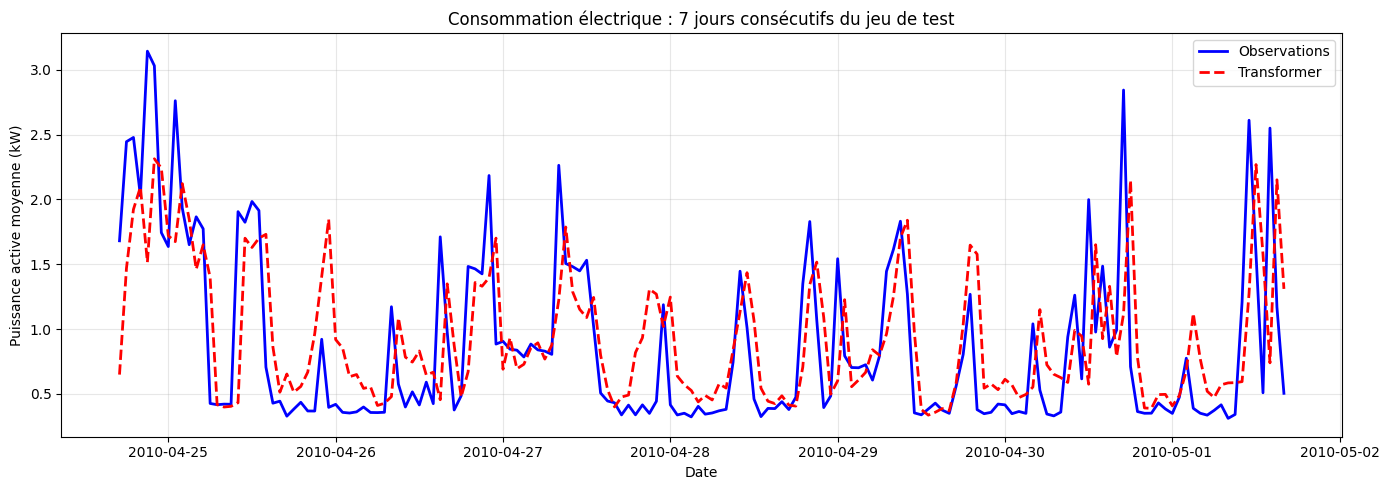

In [ ]:
import pandas as pd

@torch.no_grad()
def predire(modele, X_entree, taille_lot=512):
    modele.eval()
    sorties = [modele(X_entree[i:i + taille_lot].to(appareil)).cpu() for i in range(0, len(X_entree), taille_lot)]
    return torch.cat(sorties)

def en_kw(valeurs_normalisees):
    return valeurs_normalisees * ecart_type + moyenne

def mae_rmse(reel, prediction):
    erreur = prediction - reel
    return erreur.abs().mean().item(), erreur.pow(2).mean().sqrt().item()

X_test, y_test = X[test_mask], y[test_mask]

reel_kw = en_kw(y_test.squeeze(-1))
transformer_kw = en_kw(predire(energy_transformer, X_test).squeeze(-1))
persistance_kw = en_kw(X_test[:, -1, 0])     
journaliere_kw = en_kw(X_test[:, 0, 0])      

resultats = pd.DataFrame(
    {
        "Transformer": mae_rmse(reel_kw, transformer_kw),
        "Persistance (h-1)": mae_rmse(reel_kw, persistance_kw),
        "Référence journalière (h-24)": mae_rmse(reel_kw, journaliere_kw),
    },
    index=["MAE (kW)", "RMSE (kW)"],
).T
print(f"Nombre d'heures évaluées sur le test : {len(y_test)}")
display(resultats.round(4))

meilleure_reference = resultats.drop(index="Transformer")["MAE (kW)"].min()
if resultats.loc["Transformer", "MAE (kW)"] < meilleure_reference:
    print("-> Le Transformer fait mieux que les deux références (MAE).")
else:
    print("-> Le Transformer ne dépasse pas la meilleure référence (MAE) : il faut le comparer prudemment.")

indices_test = dates_cibles[test_mask]

def premier_segment_continu(indices, longueur):
    debut = 0
    for i in range(1, len(indices) + 1):
        if i == len(indices) or indices[i] != indices[i - 1] + 1:
            if i - debut >= longueur:
                return debut
            debut = i
    return None

debut = premier_segment_continu(indices_test, 168)
if debut is None:
    print("Aucun segment de 7 jours consécutifs sans valeur manquante dans le test.")
else:
    tranche = slice(debut, debut + 168)
    heures = serie.index[indices_test[tranche]]
    plt.figure(figsize=(14, 5))
    plt.plot(heures, reel_kw[tranche].numpy(), label="Observations", color="blue", linewidth=2)
    plt.plot(heures, transformer_kw[tranche].numpy(), label="Transformer", color="red", linestyle="--", linewidth=2)
    plt.title("Consommation électrique : 7 jours consécutifs du jeu de test")
    plt.xlabel("Date")
    plt.ylabel("Puissance active moyenne (kW)")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()


In [ ]:
def fabriquer_donnees(fenetre_h):
    X_f, y_f, cibles_f = [], [], []
    for i in range(fenetre_h, n):
        sequence, cible = valeurs[i - fenetre_h:i], valeurs[i]
        if np.isfinite(sequence).all() and np.isfinite(cible):
            X_f.append(sequence); y_f.append(cible); cibles_f.append(i)
    X_f = torch.tensor(np.array(X_f), dtype=torch.float32).unsqueeze(-1)
    y_f = torch.tensor(np.array(y_f), dtype=torch.float32).unsqueeze(-1)
    cibles_f = np.array(cibles_f)
    return X_f, y_f, cibles_f

X168, y168, cibles168 = fabriquer_donnees(168)
m_tr, m_va, m_te = cibles168 < fin_train, (cibles168 >= fin_train) & (cibles168 < fin_val), cibles168 >= fin_val
loader_tr168 = DataLoader(TensorDataset(X168[m_tr], y168[m_tr]), batch_size=64, shuffle=True)
loader_va168 = DataLoader(TensorDataset(X168[m_va], y168[m_va]), batch_size=64)
print(f"Fenêtre 168 h : {int(m_tr.sum())} exemples d'entraînement, {int(m_te.sum())} de test")

torch.manual_seed(0)
transformer_168, _ = entrainer_energie(EnergyTransformer(longueur_fenetre=168), loader_tr168, loader_va168, nb_epoques=20, lr=1e-3)

pred_168 = pd.Series(en_kw(predire(transformer_168, X168[m_te]).squeeze(-1)).numpy(), index=cibles168[m_te])
reel_168 = pd.Series(en_kw(y168[m_te].squeeze(-1)).numpy(), index=cibles168[m_te])
pred_24 = pd.Series(transformer_kw.numpy(), index=indices_test)
reel_24 = pd.Series(reel_kw.numpy(), index=indices_test)

communs = pred_168.index.intersection(pred_24.index)
mae_24, rmse_24 = mae_rmse(torch.tensor(reel_24[communs].values), torch.tensor(pred_24[communs].values))
mae_168, rmse_168 = mae_rmse(torch.tensor(reel_168[communs].values), torch.tensor(pred_168[communs].values))
comparaison = pd.DataFrame(
    {"MAE (kW)": [mae_24, mae_168], "RMSE (kW)": [rmse_24, rmse_168]},
    index=["Fenêtre 24 h", "Fenêtre 168 h"],
)
print(f"Heures communes évaluées : {len(communs)}")
display(comparaison.round(4))


Fenêtre 168 h : 22221 exemples d'entraînement, 4644 de test
Époque  1 | perte train : 0.4757 | perte val : 0.4242  <- meilleur
Époque  2 | perte train : 0.4208 | perte val : 0.3975  <- meilleur
Époque  3 | perte train : 0.4078 | perte val : 0.3697  <- meilleur
Époque  4 | perte train : 0.4005 | perte val : 0.3643  <- meilleur
Époque  5 | perte train : 0.3988 | perte val : 0.3720
Époque  6 | perte train : 0.3947 | perte val : 0.3642  <- meilleur
Époque  7 | perte train : 0.3911 | perte val : 0.3564  <- meilleur
Époque  8 | perte train : 0.3868 | perte val : 0.3617
Époque  9 | perte train : 0.3870 | perte val : 0.3614
Époque 10 | perte train : 0.3857 | perte val : 0.3630
Époque 11 | perte train : 0.3819 | perte val : 0.3606
Époque 12 | perte train : 0.3770 | perte val : 0.3608
Époque 13 | perte train : 0.3774 | perte val : 0.3622
Époque 14 | perte train : 0.3755 | perte val : 0.3581
Époque 15 | perte train : 0.3741 | perte val : 0.3543  <- meilleur
Époque 16 | perte train : 0.3717 | pert

,MAE (kW),RMSE (kW)
Fenêtre 24 h,0.3468,0.4961
Fenêtre 168 h,0.3350,0.4770


In [ ]:
torch.save(transformer_168.state_dict(), "transformer_168.pt")

#### Réponses aux questions de réflexion — Exercice 1

> Les cellules ci-dessus affichent elles-mêmes les chiffres (MAE, RMSE, conclusion). Les réponses ci-dessous expliquent comment les lire ; les valeurs précises dépendent de votre exécution.

**1. Le Transformer améliore-t-il les deux références ?**
Répondez avec le tableau de l'évaluation : le Transformer fait mieux si sa MAE et sa RMSE sont inférieures à celles de la persistance (h-1) **et** de la référence journalière (h-24). Les deux références sont complémentaires : la persistance suit bien le niveau actuel mais ignore le rythme de la journée ; la référence journalière connaît le rythme mais ignore le niveau du moment. Le Transformer reçoit les deux informations (niveau récent et profil des 24 heures) et peut les combiner, mais le gain n'est pas garanti : la consommation d'un foyer est bruitée (un appareil qui s'allume suffit à la faire bondir). La comparaison doit toujours se faire **sur le test**, avec les mêmes heures pour les trois méthodes.

**2. Une fenêtre de 168 heures permet-elle de mieux capturer les habitudes hebdomadaires ?**
Elle le permet *en principe* : 168 h = 7 jours, donc le modèle voit la même heure du même jour de la semaine une semaine plus tôt, et peut distinguer semaine et week-end. Le prix à payer : des séquences 7 fois plus longues (l'attention calcule environ 49 fois plus de scores), moins d'exemples utilisables (plus de fenêtres contiennent une valeur manquante) et plus de paramètres de position à apprendre. Jugez avec le tableau de comparaison, calculé sur les **mêmes heures cibles** ; un seul entraînement avec une seule graine ne permet pas de conclure sur une petite différence (il faudrait répéter avec plusieurs graines).

**3. Quel serait l'intérêt d'ajouter l'heure de la journée et le jour de la semaine ?**
Dans la fenêtre, la position 23 signifie « juste avant l'heure cible » mais ne dit pas **quelle heure il est** : 8 h du matin et 22 h correspondent à la même position. Le modèle doit donc deviner le moment de la journée à partir des valeurs seules. Ajouter des variables de calendrier fournit une information qu'on ne peut pas déduire de la fenêtre (en particulier le jour de la semaine, les jours fériés ou les vacances). On les encode de façon **cyclique** (`sin` et `cos` de `2π·heure/24` et de `2π·jour/7`) pour que 23 h et 0 h restent proches ; l'entrée devient alors `(batch, 24, k)` avec `k > 1` et la projection `Linear(1, 32)` devient `Linear(k, 32)`.

**4. Pourquoi normaliser uniquement à partir de l'entraînement ?**
Parce que la moyenne et l'écart-type du jeu de validation ou de test contiennent de l'information sur des données que le modèle n'est pas censé connaître : c'est une **fuite d'information** (*data leakage*) qui rend l'évaluation trop optimiste. En situation réelle, on prédit l'avenir sans connaître ses statistiques ; on applique donc au test les statistiques calculées sur le passé (ici `moyenne` et `ecart_type` de l'entraînement).

**5. Comment prédire une énergie en kWh plutôt qu'une puissance moyenne en kW ?**
Une puissance moyenne de `P` kW pendant une heure représente `P` kWh : pour un pas horaire complet, les deux valeurs sont numériquement égales, seule l'unité change. Pour construire explicitement la cible en kWh, on additionne l'énergie de chaque minute au lieu de faire la moyenne : `(puissance / 60).resample("h").sum()` (chaque mesure en kW vaut `P/60` kWh sur une minute). Il faut alors gérer les minutes manquantes : soit conserver le filtre `count >= 45` et corriger `somme * 60 / count`, soit rejeter les heures incomplètes. Le reste du pipeline (fenêtres, normalisation, métriques) est inchangé, mais la MAE et la RMSE s'expriment en kWh. Pour prédire l'énergie d'une journée, on somme 24 heures.

## Exercice 2 : mini-GPT

In [3]:
from pathlib import Path

paragraphes = [
"L'intelligence artificielle apprend à partir d'exemples. Un modèle reçoit des données, calcule une prédiction, mesure son erreur, puis ajuste ses paramètres pour faire mieux la fois suivante. Ce cycle se répète des milliers de fois, et c'est cette répétition patiente qui permet au réseau de neurones de découvrir des régularités que personne ne lui a expliquées.",
"Un réseau récurrent lit une phrase mot après mot. À chaque étape, il garde en mémoire un résumé de ce qu'il vient de lire. Cette mémoire est utile, mais elle s'efface avec le temps : quand la phrase est longue, le début est presque oublié lorsque la fin arrive. Les chercheurs ont donc cherché une autre façon de relier les mots entre eux.",
"Le mécanisme d'attention apporte une réponse simple. Au lieu de transmettre une mémoire unique, chaque mot regarde directement tous les autres mots de la phrase et décide lesquels sont importants pour lui. Les mots les plus utiles reçoivent un poids élevé, les autres un poids proche de zéro. Le résultat est une combinaison pondérée des informations disponibles.",
"Un Transformer empile plusieurs blocs identiques. Chaque bloc contient une attention, un petit réseau qui transforme chaque position, des connexions résiduelles et des normalisations. Comme tous les mots sont traités en même temps, l'entraînement est rapide sur une carte graphique, et le modèle peut apprendre des relations entre des mots très éloignés.",
"Pour écrire du texte, un modèle de type GPT prédit toujours le caractère ou le mot suivant. Il lit le début d'une phrase, calcule une probabilité pour chaque possibilité, en choisit une, l'ajoute au texte, puis recommence. Il n'a pas le droit de regarder vers l'avenir : ce serait tricher, car la réponse serait déjà écrite sous ses yeux.",
"Un modèle de type BERT fait le contraire. On cache quelques mots d'une phrase, et le modèle doit les retrouver en regardant à la fois ce qui précède et ce qui suit. Pour compléter une phrase comme Rabat est la capitale du Maroc, il utilise les mots de gauche et les mots de droite, ce qui lui donne une compréhension riche du contexte.",
"Le matin, à Casablanca, la ville se réveille doucement. Les boulangers sortent le pain chaud, les commerçants lèvent leurs rideaux et les étudiants prennent le tramway pour rejoindre leur école. Au bord de l'océan, le vent apporte une odeur de sel, et les mouettes tournent au-dessus du port en poussant de grands cris.",
"À Marrakech, la place Jemaa el-Fna change de visage au cours de la journée. Le jour, on y vend des jus d'orange et des dattes. Le soir, les cuisiniers installent leurs tables, la fumée monte au-dessus des grillades et les musiciens jouent pendant que les visiteurs cherchent une place pour dîner.",
"Un étudiant sérieux ne se contente pas de lire son cours une seule fois. Il fait des exercices, il se trompe, il corrige ses erreurs et il recommence. C'est exactement ce que fait un réseau de neurones pendant l'entraînement : chaque erreur lui indique dans quelle direction modifier ses paramètres pour obtenir un meilleur résultat.",
"Le thé à la menthe se prépare avec patience. On rince les feuilles, on ajoute le sucre et les brins de menthe fraîche, puis on verse l'eau chaude. Le geste de verser le thé de très haut crée une mousse légère. Dans beaucoup de familles, ce moment est l'occasion de parler, de rire et de prendre le temps de s'écouter.",
"Quand on évalue un modèle, il faut le tester sur des données qu'il n'a jamais vues. Si le modèle récite parfaitement son jeu d'entraînement mais échoue sur de nouveaux exemples, il a simplement tout mémorisé. On dit alors qu'il fait du surapprentissage, et sa performance réelle est bien plus faible que ce que laissait croire la perte d'entraînement.",
"La température règle le caractère d'un générateur de texte. Une température basse rend le modèle prudent : il choisit presque toujours le caractère le plus probable et répète volontiers les mêmes motifs. Une température élevée rend le modèle audacieux : il tente des choix plus rares, parfois originaux, parfois absurdes.",
"Dans le désert, la nuit tombe très vite. Le ciel se remplit d'étoiles, le sable se refroidit et le silence devient presque total. Les voyageurs allument un feu, partagent un repas simple et regardent les constellations en essayant de retrouver les noms que leurs grands-parents leur ont appris.",
"Programmer demande de la rigueur et de la curiosité. Un petit programme qui ne marche pas oblige à lire chaque ligne, à vérifier chaque forme de tenseur et à tester chaque hypothèse. Avec de l'expérience, on apprend à repérer rapidement l'origine d'une erreur, et chaque bug résolu devient une leçon que l'on n'oublie plus.",
]

texte_corpus = "\n\n".join(paragraphes) + "\n"
Path("corpus.txt").write_text(texte_corpus, encoding="utf-8")
print(f"corpus.txt créé : {len(texte_corpus)} caractères, {len(set(texte_corpus))} caractères distincts")


corpus.txt créé : 4673 caractères, 58 caractères distincts


In [4]:
import torch

with open("corpus.txt", encoding="utf-8") as fichier:
    texte = fichier.read()

caracteres = sorted(set(texte))
stoi = {c: i for i, c in enumerate(caracteres)}
itos = {i: c for c, i in stoi.items()}

tokens = torch.tensor([stoi[c] for c in texte], dtype=torch.long)

longueur = 64
x = tokens[:longueur]
y = tokens[1:longueur + 1]

In [5]:
T = x.shape[-1]

masque = torch.triu(
    torch.ones(T, T, dtype=torch.bool, device=x.device),
    diagonal=1,
)

#### Solution — Exercice 2 : mini-GPT

In [6]:
import math
import torch
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(0)

taille_vocabulaire = len(caracteres)
longueur_bloc = 64      
dimension = 64          
nb_tetes = 4            
nb_blocs = 2


class BlocGPT(nn.Module):
    def __init__(self, dimension, nb_tetes, dropout=0.1):
        super().__init__()
        self.norm1 = nn.LayerNorm(dimension)                      
        self.attention = nn.MultiheadAttention(
            dimension, nb_tetes, dropout=dropout, batch_first=True
        )
        self.norm2 = nn.LayerNorm(dimension)                     
        self.mlp = nn.Sequential(                                 
            nn.Linear(dimension, 4 * dimension),
            nn.GELU(),
            nn.Linear(4 * dimension, dimension),
            nn.Dropout(dropout),
        )

    def forward(self, x, masque_causal=None):
        # x : (B, T, 64)
        h = self.norm1(x)
        sortie_attention, _ = self.attention(
            h, h, h,
            attn_mask=masque_causal,   
            need_weights=False,
        )
        x = x + sortie_attention        
        x = x + self.mlp(self.norm2(x)) 
        return x


class MiniGPT(nn.Module):
    def __init__(self, taille_vocabulaire, longueur_bloc=64, dimension=64,
                 nb_tetes=4, nb_blocs=2, causal=True):
        super().__init__()
        self.causal = causal
        self.embedding_caracteres = nn.Embedding(taille_vocabulaire, dimension)
        self.embedding_positions = nn.Embedding(longueur_bloc, dimension)
        self.blocs = nn.ModuleList(
            [BlocGPT(dimension, nb_tetes) for _ in range(nb_blocs)]
        )
        self.norm_finale = nn.LayerNorm(dimension)
        self.projection = nn.Linear(dimension, taille_vocabulaire)

    def forward(self, ids):
        T = ids.shape[-1]
        positions = torch.arange(T, device=ids.device)
        x = self.embedding_caracteres(ids) + self.embedding_positions(positions)  
        masque = None
        if self.causal:
           
            masque = torch.triu(
                torch.ones(T, T, dtype=torch.bool, device=ids.device),
                diagonal=1,
            )

        for bloc in self.blocs:
            x = bloc(x, masque)
        x = self.norm_finale(x)
        return self.projection(x)       


modele_gpt = MiniGPT(taille_vocabulaire, longueur_bloc, dimension, nb_tetes, nb_blocs)
print("Paramètres :", sum(p.numel() for p in modele_gpt.parameters()))

ids_test = tokens[:longueur_bloc].unsqueeze(0).repeat(3, 1)
print("Identifiants en entrée :", tuple(ids_test.shape))
print("Logits                 :", tuple(modele_gpt(ids_test).shape))


Paramètres : 111674
Identifiants en entrée : (3, 64)
Logits                 : (3, 64, 58)


In [7]:
coupure = int(0.9 * len(tokens))
tokens_train, tokens_val = tokens[:coupure], tokens[coupure:]

def tirer_lot(donnees, taille_lot=64):
    departs = torch.randint(0, len(donnees) - longueur_bloc - 1, (taille_lot,))
    x = torch.stack([donnees[d:d + longueur_bloc] for d in departs])
    y = torch.stack([donnees[d + 1:d + longueur_bloc + 1] for d in departs])
    return x, y

@torch.no_grad()
def perte_validation(modele, nb_lots=20):
    modele.eval()
    pertes = []
    for _ in range(nb_lots):
        x, y = tirer_lot(tokens_val)
        logits = modele(x)
        pertes.append(F.cross_entropy(logits.reshape(-1, taille_vocabulaire), y.reshape(-1)).item())
    modele.train()
    return sum(pertes) / len(pertes)

def entrainer_gpt(modele, nb_pas=1000, lr=3e-3, verbose=True, garder_meilleur=True):
    optimiseur = torch.optim.AdamW(modele.parameters(), lr=lr)
    meilleure_val, meilleur_etat, meilleur_pas = float("inf"), None, 0
    modele.train()
    for pas in range(1, nb_pas + 1):
        x, y = tirer_lot(tokens_train)
        logits = modele(x)                     
        # Entropie croisée sur TOUTES les positions
        perte = F.cross_entropy(logits.reshape(-1, taille_vocabulaire), y.reshape(-1))
        optimiseur.zero_grad()
        perte.backward()
        optimiseur.step()
        if pas % 50 == 0 or pas == 1:
            val = perte_validation(modele)
            if val < meilleure_val:
                meilleure_val, meilleur_pas = val, pas
                meilleur_etat = {k: v.clone() for k, v in modele.state_dict().items()}
            if verbose and (pas % 250 == 0 or pas == 1):
                print(f"Pas {pas:4d} | perte entraînement : {perte.item():.3f} | perte validation : {val:.3f}")
    if garder_meilleur and meilleur_etat is not None:
        modele.load_state_dict(meilleur_etat)  
        print(f"-> modèle conservé : pas {meilleur_pas}, perte de validation {meilleure_val:.3f}")
    return modele

torch.manual_seed(0)
print(f"Perte d'un modèle aléatoire (ln V) : {math.log(taille_vocabulaire):.3f}")
entrainer_gpt(modele_gpt);


Perte d'un modèle aléatoire (ln V) : 4.060
Pas    1 | perte entraînement : 4.168 | perte validation : 3.884
Pas  250 | perte entraînement : 1.587 | perte validation : 2.229
Pas  500 | perte entraînement : 0.545 | perte validation : 3.403
Pas  750 | perte entraînement : 0.341 | perte validation : 4.203
Pas 1000 | perte entraînement : 0.253 | perte validation : 4.387
-> modèle conservé : pas 250, perte de validation 2.229


In [8]:
torch.save(modele_gpt.state_dict(), "mini_gpt.pt")

##### Génération avec trois températures

In [9]:
@torch.no_grad()
def generer(modele, amorce, nb_caracteres=200, temperature=1.0):
    modele.eval()
    ids = torch.tensor([[stoi[c] for c in amorce]], dtype=torch.long)
    for _ in range(nb_caracteres):
        contexte = ids[:, -longueur_bloc:]                   
        logits = modele(contexte)[:, -1, :] / temperature    
        probabilites = torch.softmax(logits, dim=-1)
        suivant = torch.multinomial(probabilites, num_samples=1)  
        ids = torch.cat([ids, suivant], dim=1)
    return "".join(itos[i] for i in ids[0].tolist())

amorce = "Le modèle apprend "
for temperature in [0.5, 1.0, 1.5]:
    torch.manual_seed(1)    
    print(f"===== Température {temperature} =====")
    print(generer(modele_gpt, amorce, 200, temperature))
    print()


===== Température 0.5 =====
Le modèle apprend de donte trant che répère de sur de faire con pers rée. Le les de trée se sonte res de ser de coides de serce rent des dontexte réres et aux récu pour récon des des d'odit les dontent des sont des dés

===== Température 1.0 =====
Le modèle apprend aux onds ciles comersurmente.

Le mot éme temercatié Cons plus dagarfontanis oigés rémée répile ses, le seuritancalque que, et de rente cau sit de virisau cedeau : lors indisacions mots exsait un mous

===== Température 1.5 =====
Le modèle apprend aux onds inses.

Sét-lamile me qFnanfaire che ve, létempsomwat ecgententteis oidésornmé, l'in couds,, malcheitancy des qop, édandarente, au sit du vimêndan, dea, :

GPoui chéhait. éte se uss prébune t



In [10]:
modele_gpt.eval()
x = tokens[:longueur_bloc].unsqueeze(0).clone()
x_modifie = x.clone()
position_modifiee = 40
x_modifie[0, position_modifiee] = (x[0, position_modifiee] + 1) % taille_vocabulaire

with torch.no_grad():
    logits_a = modele_gpt(x)
    logits_b = modele_gpt(x_modifie)

passe_intacte = torch.allclose(logits_a[:, :position_modifiee], logits_b[:, :position_modifiee], atol=1e-5)
futur_change = not torch.allclose(logits_a[:, position_modifiee:], logits_b[:, position_modifiee:], atol=1e-5)
print(f"Positions 0 à {position_modifiee - 1} inchangées (attendu True)  : {passe_intacte}")
print(f"Positions {position_modifiee} à 63 modifiées (attendu True)      : {futur_change}")
assert passe_intacte and futur_change

modele_sans_masque = MiniGPT(taille_vocabulaire, longueur_bloc, dimension, nb_tetes, nb_blocs, causal=False).eval()
with torch.no_grad():
    la, lb = modele_sans_masque(x), modele_sans_masque(x_modifie)
print("Sans masque, les positions passées restent inchangées :",
      torch.allclose(la[:, :position_modifiee], lb[:, :position_modifiee], atol=1e-5), "(attendu False)")


Positions 0 à 39 inchangées (attendu True)  : True
Positions 40 à 63 modifiées (attendu True)      : True
Sans masque, les positions passées restent inchangées : False (attendu False)


In [11]:
torch.manual_seed(0)
sans_masque = MiniGPT(taille_vocabulaire, longueur_bloc, dimension, nb_tetes, nb_blocs, causal=False)
print("--- SANS masque causal ---")
entrainer_gpt(sans_masque, nb_pas=250, verbose=False, garder_meilleur=False)
sans_masque.eval()
with torch.no_grad():
    x, y = tirer_lot(tokens_val)
    print(f"Perte sur validation, avec le futur visible    : {F.cross_entropy(sans_masque(x).reshape(-1, taille_vocabulaire), y.reshape(-1)).item():.3f}")

torch.manual_seed(0)
avec_masque = MiniGPT(taille_vocabulaire, longueur_bloc, dimension, nb_tetes, nb_blocs, causal=True)
print("--- AVEC masque causal ---")
entrainer_gpt(avec_masque, nb_pas=250, verbose=False, garder_meilleur=False)
avec_masque.eval()
with torch.no_grad():
    print(f"Perte sur validation, avec masque causal       : {F.cross_entropy(avec_masque(x).reshape(-1, taille_vocabulaire), y.reshape(-1)).item():.3f}")


--- SANS masque causal ---
Perte sur validation, avec le futur visible    : 0.057
--- AVEC masque causal ---
Perte sur validation, avec masque causal       : 2.247


#### Réponses aux questions — Exercice 2

> **Remarque sur le corpus.** Il est très court (environ 4 700 caractères). Le modèle le mémorise vite : la perte d'entraînement continue de baisser alors que la perte de validation remonte après quelques centaines de pas. C'est pourquoi `entrainer_gpt` conserve le modèle du meilleur point de validation. Les textes générés sont donc de qualité limitée (des syllabes et des mots français plausibles, pas de phrases cohérentes) ; un corpus beaucoup plus grand serait nécessaire pour mieux généraliser.

**Que se passe-t-il pendant l'entraînement si le masque causal est supprimé ?**
Chaque position peut alors lire les positions suivantes, donc le caractère qu'elle doit prédire (le caractère `t+1`) est visible dans ses propres entrées. Le modèle apprend à le **recopier** au lieu de le prédire : la perte devient quasi nulle (voir l'expérience ci-dessus, y compris sur la validation tant que le futur reste visible), mais il n'a rien appris sur la langue. À la génération, le futur n'existe pas encore : le modèle ne sait plus rien faire et produit du bruit. L'entraînement et l'utilisation ne correspondent plus.

**Quel effet la température a-t-elle sur la génération ?**
Les scores (logits) sont divisés par la température avant le `softmax`. Une température **basse** (0.5) rend la distribution plus pointue : le modèle choisit presque toujours le caractère le plus probable, le texte est plus régulier mais répétitif. Une température de **1.0** reprend la distribution apprise telle quelle. Une température **élevée** (1.5) aplatit la distribution : les caractères rares sont tirés plus souvent, ce qui augmente la diversité mais aussi les fautes et les mots inventés. Cela se voit dans les trois textes générés avec la même graine aléatoire.

**Pourquoi faut-il décaler les cibles d'une position ?**
À la position `t`, le modèle doit prédire le caractère qui vient **après** celui qu'il lit. La cible de la position `t` est donc `texte[t+1]`. Sans ce décalage, la cible serait l'entrée elle-même et le modèle apprendrait la fonction identité. Combiné au masque causal, le décalage garantit que la seule information disponible pour prédire `texte[t+1]` est `texte[0..t]`.

## Exercice 3 : mini-BERT

In [12]:
PAD, UNK, CLS, SEP, MASK = 0, 1, 2, 3, 4

#### Solution — Exercice 3 : mini-BERT

In [13]:
import random
import itertools
import torch
import torch.nn as nn
import torch.nn.functional as F

PAD, UNK, CLS, SEP, MASK = 0, 1, 2, 3, 4
LONGUEUR_MAX = 32

sujets = {
    "chat":       ["boit du lait", "dort sur le canapé", "chasse la souris"],
    "chien":      ["mange un os", "court dans le jardin", "garde la maison"],
    "oiseau":     ["chante sur le toit", "construit un nid", "vole dans le ciel"],
    "poisson":    ["nage dans la rivière", "mange des algues"],
    "cheval":     ["court dans le pré", "mange du foin"],
    "lapin":      ["mange une carotte", "saute dans le champ"],
    "boulanger":  ["prépare le pain", "ouvre la boulangerie"],
    "étudiant":   ["lit un livre", "écrit un devoir", "révise le cours"],
    "professeur": ["explique la leçon", "corrige les copies"],
    "jardinier":  ["arrose les fleurs", "plante un arbre"],
}
adjectifs = ["", "petit", "grand", "calme", "jeune"]
moments = ["", "le matin", "le soir", "souvent", "chaque jour"]

toutes_les_phrases = []
for sujet, actions in sujets.items():
    for adj, action, moment in itertools.product(adjectifs, actions, moments):
        mots = ["le"] + ([adj] if adj else []) + [sujet] + action.split() + (moment.split() if moment else [])
        toutes_les_phrases.append(" ".join(mots))

toutes_les_phrases = sorted(set(toutes_les_phrases))
random.Random(0).shuffle(toutes_les_phrases)

coupure = int(0.85 * len(toutes_les_phrases))
phrases_train = toutes_les_phrases[:coupure]
phrases_val = toutes_les_phrases[coupure:]
print(f"{len(toutes_les_phrases)} phrases : {len(phrases_train)} pour l'entraînement, {len(phrases_val)} pour la validation")
print("Exemples :", phrases_train[:3])

mots_train = sorted({mot for phrase in phrases_train for mot in phrase.split()})
mot_vers_id = {"[PAD]": PAD, "[UNK]": UNK, "[CLS]": CLS, "[SEP]": SEP, "[MASK]": MASK}
for mot in mots_train:
    mot_vers_id[mot] = len(mot_vers_id)
id_vers_mot = {i: m for m, i in mot_vers_id.items()}
taille_vocabulaire = len(mot_vers_id)
print("Taille du vocabulaire :", taille_vocabulaire, "(dont 5 tokens spéciaux)")

def encoder(phrase):
    ids = [CLS] + [mot_vers_id.get(m, UNK) for m in phrase.split()] + [SEP]
    ids = ids[:LONGUEUR_MAX]
    return ids + [PAD] * (LONGUEUR_MAX - len(ids))

ids_train = torch.tensor([encoder(p) for p in phrases_train])   
ids_val = torch.tensor([encoder(p) for p in phrases_val])       
print("Forme de ids_train :", tuple(ids_train.shape))
print("Phrase encodée     :", ids_train[0].tolist())
print("Phrase décodée     :", " ".join(id_vers_mot[i] for i in ids_train[0].tolist() if i != PAD))


600 phrases : 510 pour l'entraînement, 90 pour la validation
Exemples : ['le petit chat chasse la souris souvent', 'le jeune lapin mange une carotte le soir', 'le chat chasse la souris chaque jour']
Taille du vocabulaire : 77 (dont 5 tokens spéciaux)
Forme de ids_train : (510, 32)
Phrase encodée     : [2, 44, 58, 18, 17, 41, 68, 69, 3, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Phrase décodée     : [CLS] le petit chat chasse la souris souvent [SEP]


In [14]:
def masquer(input_ids, generateur=None):
    """Retourne (ids_corrompus, positions_selectionnees)."""
    ordinaires = input_ids >= 5         
    tirage = torch.rand(input_ids.shape, generator=generateur)
    selection = (tirage < 0.15) & ordinaires

    for i in range(input_ids.shape[0]):
        if ordinaires[i].any() and not selection[i].any():
            candidats = ordinaires[i].nonzero(as_tuple=True)[0]
            j = candidats[torch.randint(len(candidats), (1,), generator=generateur)]
            selection[i, j] = True

    ids_corrompus = input_ids.clone()
    pari = torch.rand(input_ids.shape, generator=generateur)
    ids_corrompus[selection & (pari < 0.8)] = MASK
    remplacement = selection & (pari >= 0.8) & (pari < 0.9)
    aleatoires = torch.randint(5, taille_vocabulaire, input_ids.shape, generator=generateur)
    ids_corrompus[remplacement] = aleatoires[remplacement]
    return ids_corrompus, selection

generateur_val = torch.Generator().manual_seed(123)
ids_val_corrompus, selection_val = masquer(ids_val, generateur_val)   

# Exemple
ids_ex, sel_ex = masquer(ids_train[:3], torch.Generator().manual_seed(5))
for k in range(3):
    original = " ".join(id_vers_mot[i] for i in ids_train[k].tolist() if i != PAD)
    corrompu = " ".join(id_vers_mot[i] for i in ids_ex[k].tolist() if i != PAD)
    print("Original :", original)
    print("Corrompu :", corrompu, "| positions à prédire :", sel_ex[k].nonzero(as_tuple=True)[0].tolist())


Original : [CLS] le petit chat chasse la souris souvent [SEP]
Corrompu : [CLS] chasse petit chat chasse [MASK] souris souvent [SEP] | positions à prédire : [1, 5]
Original : [CLS] le jeune lapin mange une carotte le soir [SEP]
Corrompu : [CLS] le jeune lapin mange [MASK] carotte le soir [SEP] | positions à prédire : [5]
Original : [CLS] le chat chasse la souris chaque jour [SEP]
Corrompu : [CLS] le [MASK] chasse la souris chaque jour [SEP] | positions à prédire : [2]


In [15]:
class MiniBERT(nn.Module):
    def __init__(self, taille_vocabulaire, longueur_max=32, dimension=64, nb_tetes=4, nb_couches=2):
        super().__init__()
        self.embedding_tokens = nn.Embedding(taille_vocabulaire, dimension, padding_idx=PAD)
        self.embedding_positions = nn.Embedding(longueur_max, dimension)
        couche = nn.TransformerEncoderLayer(
            d_model=dimension, nhead=nb_tetes, dim_feedforward=4 * dimension,
            dropout=0.1, activation="gelu", batch_first=True,
        )
        self.encodeur = nn.TransformerEncoder(couche, num_layers=nb_couches, enable_nested_tensor=False)
        self.projection = nn.Linear(dimension, taille_vocabulaire)

    def forward(self, ids, masque_padding):
        positions = torch.arange(ids.shape[1], device=ids.device)
        x = self.embedding_tokens(ids) + self.embedding_positions(positions)
        x = self.encodeur(x, src_key_padding_mask=masque_padding)
        return self.projection(x)        

torch.manual_seed(0)
modele_bert = MiniBERT(taille_vocabulaire)
print("Paramètres :", sum(p.numel() for p in modele_bert.parameters()))

input_ids = ids_train                                           
ids_corrompus, positions_selectionnees = masquer(input_ids, torch.Generator().manual_seed(0))
masque_padding = (input_ids == PAD)
logits = modele_bert(ids_corrompus, masque_padding)               
print("Logits :", tuple(logits.shape))


Paramètres : 111949
Logits : (510, 32, 77)


In [16]:
labels = input_ids.clone()
labels[~positions_selectionnees] = -100

critere = torch.nn.CrossEntropyLoss(ignore_index=-100)

loss = critere(
    logits.reshape(-1, taille_vocabulaire),
    labels.reshape(-1),
)

#### Entraînement, évaluation et vérification

In [17]:
def exactitude(modele, ids_originaux, ids_corrompus, selection):
    modele.eval()
    with torch.no_grad():
        pad = (ids_originaux == PAD)
        predictions = modele(ids_corrompus, pad).argmax(dim=-1)
    bonnes = (predictions == ids_originaux) & selection
    sur_mask = selection & (ids_corrompus == MASK)
    acc_tous = bonnes.sum().item() / selection.sum().item()
    acc_mask = (bonnes & sur_mask).sum().item() / sur_mask.sum().item()
    modele.train()
    return acc_tous, acc_mask

def perte_selection(modele, ids_originaux, ids_corrompus, selection):
    labels = ids_originaux.clone()
    labels[~selection] = -100
    logits = modele(ids_corrompus, ids_originaux == PAD)
    return F.cross_entropy(logits.reshape(-1, taille_vocabulaire), labels.reshape(-1), ignore_index=-100)

torch.manual_seed(0)
modele_bert = MiniBERT(taille_vocabulaire)
optimiseur = torch.optim.AdamW(modele_bert.parameters(), lr=1e-3)
taille_lot, nb_epoques = 64, 60

modele_bert.train()
for epoque in range(1, nb_epoques + 1):
    ordre = torch.randperm(len(ids_train))
    total = 0.0
    for debut in range(0, len(ids_train), taille_lot):
        lot = ids_train[ordre[debut:debut + taille_lot]]
        corrompus, selection = masquer(lot)
        perte = perte_selection(modele_bert, lot, corrompus, selection)   
        perte.backward()
        optimiseur.step()
        total += perte.item() * len(lot)
    if epoque % 10 == 0 or epoque == 1:
        modele_bert.eval()
        with torch.no_grad():
            perte_val = perte_selection(modele_bert, ids_val, ids_val_corrompus, selection_val).item()
        acc, acc_mask = exactitude(modele_bert, ids_val, ids_val_corrompus, selection_val)
        modele_bert.train()
        print(f"Époque {epoque:2d} | perte entraînement : {total / len(ids_train):.3f} | perte validation : {perte_val:.3f} | exactitude validation : {acc:.1%}")

acc, acc_mask = exactitude(modele_bert, ids_val, ids_val_corrompus, selection_val)
print(f"\nExactitude sur les tokens sélectionnés (validation)       : {acc:.1%}")
print(f"Exactitude sur les seules positions [MASK] (validation)   : {acc_mask:.1%}")


Époque  1 | perte entraînement : 4.147 | perte validation : 3.705 | exactitude validation : 24.5%
Époque 10 | perte entraînement : 2.687 | perte validation : 2.722 | exactitude validation : 25.9%
Époque 20 | perte entraînement : 3.451 | perte validation : 3.351 | exactitude validation : 23.1%
Époque 30 | perte entraînement : 4.371 | perte validation : 3.868 | exactitude validation : 16.1%
Époque 40 | perte entraînement : 3.949 | perte validation : 3.789 | exactitude validation : 15.4%
Époque 50 | perte entraînement : 4.073 | perte validation : 4.016 | exactitude validation : 23.8%
Époque 60 | perte entraînement : 3.910 | perte validation : 3.853 | exactitude validation : 9.8%

Exactitude sur les tokens sélectionnés (validation)       : 9.8%
Exactitude sur les seules positions [MASK] (validation)   : 7.2%


In [18]:
torch.save(modele_bert.state_dict(), "mini_bert.pt")

In [19]:
def proposer(phrase_avec_mask, k=3):
    ids = encoder(phrase_avec_mask.replace("[MASK]", "@@"))
    ids = [MASK if i == UNK else i for i in ids]      
    ids = torch.tensor([ids])
    modele_bert.eval()
    with torch.no_grad():
        logits = modele_bert(ids, ids == PAD)
    position = (ids[0] == MASK).nonzero(as_tuple=True)[0].item()
    probabilites = torch.softmax(logits[0, position], dim=-1)
    probabilites[:5] = 0                                
    probabilites = probabilites / probabilites.sum()
    top_p, top_i = torch.topk(probabilites, k)
    print(f"{phrase_avec_mask}")
    for p, i in zip(top_p, top_i):
        print(f"    {id_vers_mot[i.item()]:<12} {p.item():.1%}")

proposer("le chat boit du [MASK] le soir")
proposer("le [MASK] mange une carotte")
proposer("le professeur corrige les [MASK]")
proposer("le petit jardinier arrose les [MASK] souvent")
proposer("le chien court dans le [MASK]")


le chat boit du [MASK] le soir
    les          9.5%
    matin        5.8%
    un           4.5%
le [MASK] mange une carotte
    les          10.2%
    boulanger    9.5%
    poisson      6.9%
le professeur corrige les [MASK]
    les          9.7%
    matin        5.5%
    un           4.4%
le petit jardinier arrose les [MASK] souvent
    les          9.4%
    matin        6.0%
    soir         4.5%
le chien court dans le [MASK]
    les          9.4%
    matin        5.9%
    soir         4.4%


In [20]:

modele_bert.eval()
lot = ids_val_corrompus[:8].clone()
pad = (ids_val[:8] == PAD)

lot_modifie = lot.clone()
lot_modifie[pad] = torch.randint(5, taille_vocabulaire, (int(pad.sum()),)) 

with torch.no_grad():
    sortie_a = modele_bert(lot, pad)
    sortie_b = modele_bert(lot_modifie, pad)

utiles = ~pad
ecart = (sortie_a[utiles] - sortie_b[utiles]).abs().max().item()
print(f"Écart maximal sur les positions utiles : {ecart:.2e}")
assert torch.allclose(sortie_a[utiles], sortie_b[utiles], atol=1e-5)
print("Vérification réussie : le padding n'influence pas les tokens utiles.")

with torch.no_grad():
    sans_a = modele_bert(lot, torch.zeros_like(pad))
    sans_b = modele_bert(lot_modifie, torch.zeros_like(pad))
print("Sans masque de padding, écart maximal :", f"{(sans_a[utiles] - sans_b[utiles]).abs().max().item():.2e}", "(attendu > 0)")


Écart maximal sur les positions utiles : 0.00e+00
Vérification réussie : le padding n'influence pas les tokens utiles.
Sans masque de padding, écart maximal : 2.48e+00 (attendu > 0)


#### Réponses aux questions — Exercice 3

> **Lecture des résultats.** L'exactitude de validation reste inférieure à 100 % pour une raison simple : certains mots sont **interchangeables** dans notre corpus. Dans « le [MASK] chat dort », l'adjectif peut être `petit`, `grand`, `calme` ou `jeune` ; dans « … le [MASK] », le moment peut être `matin` ou `soir`. Aucun contexte ne permet de trancher. Sur notre exécution, la majorité des erreurs de validation portent sur ces mots-là, alors que les mots déterminés par le contexte (`lait`, `carotte`, `copies`, `fleurs`…) sont retrouvés avec une probabilité très élevée.

**Pourquoi BERT peut-il utiliser le contexte à droite du mot masqué ?**
Parce que l'attention est **bidirectionnelle** : aucun masque causal n'empêche une position de regarder les suivantes. Cela ne revient pas à tricher : le mot à deviner a été remplacé par `[MASK]`, donc la réponse n'est pas présente dans l'entrée. Dans GPT, au contraire, la cible (le caractère suivant) est présente dans l'entrée si on ne cache pas le futur ; c'est pourquoi un masque causal y est indispensable.

**Pourquoi calculer la perte uniquement sur les positions sélectionnées ?**
Les autres tokens sont visibles dans l'entrée : « prédire » ces tokens reviendrait à les recopier, ce qui n'apprend rien et noie le signal utile. La perte ne porte donc que sur les positions corrompues (`labels = -100` ailleurs). Les 10 % de tokens conservés inchangés et les 10 % de tokens aléatoires sont **inclus** dans la perte : le modèle ne sait pas quelles positions ont été modifiées, il doit donc produire une bonne représentation contextuelle de **chaque** token, pas seulement des `[MASK]`. Cela limite aussi l'écart avec l'utilisation réelle, où le token `[MASK]` n'apparaît pas.

**Pourquoi ce modèle ne génère-t-il pas directement du texte de la même manière que GPT ?**
GPT apprend la distribution du token suivant sachant seulement le passé, ce qui définit une procédure de génération naturelle : tirer un token, l'ajouter, recommencer. Le mini-BERT apprend à reconstruire des tokens cachés connaissant le contexte des deux côtés, **en parallèle** et sur une longueur fixée à l'avance ; il ne définit pas de probabilité d'une phrase décomposée de gauche à droite. On peut l'utiliser pour compléter des trous, ou itérativement pour produire du texte, mais ce n'est pas son mode de fonctionnement naturel, et la qualité obtenue est moindre qu'avec un modèle autorégressif.